# 05 — Validation croisée spatiale


## 0. Imports et choix du processeur

In [1]:
import copy
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from unet import UNet

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")
print("Calcul sur :", DEVICE)

Calcul sur : mps


## 1. Paramètres


In [2]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODELE_DIR = Path("modeles")

NOM_ESSAI = "unet_sans_poids"   # l'essai à valider (nom donné dans le notebook 03)

with open(MODELE_DIR / f"{NOM_ESSAI}_resultats.json") as f:
    HP = json.load(f)["hyperparametres"]
POIDS_CLASSES = HP["poids_classes"]
ANNEES_ENTRAINEMENT = [int(a) for a in HP["annees"].split("+")]
BASE, BATCH, LR, WEIGHT_DECAY = HP["base"], HP["batch"], HP["lr"], HP["weight_decay"]
EPOQUES_MAX, PATIENCE, AUGMENTATION = HP["epoques_max"], HP["patience"], HP["augmentation"]
GRAINE = 42
print(f"Essai {NOM_ESSAI} :", HP)

Essai unet_sans_poids : {'poids_classes': False, 'annees': '2021+2022', 'base': 32, 'batch': 16, 'lr': 0.001, 'weight_decay': 0.0001, 'epoques_max': 150, 'patience': 25, 'augmentation': True}


## 2. Chargement de tous les patchs


In [3]:
with open(DATA_DIR / "config_patchs.json") as f:
    CONFIG = json.load(f)
IGNORE = CONFIG["ignore"]
CLASSES = {int(k): v for k, v in CONFIG["classes"].items()}
NOMS = [CLASSES[k]["nom"] for k in sorted(CLASSES)]
N_CLASSES = len(NOMS)
N_BANDES = len(CONFIG["bandes"])
N_PLIS = CONFIG["n_plis"]

morceaux = [np.load(DATA_DIR / f"patchs_{s}.npz") for s in ["train", "val", "test"]]
X = np.concatenate([d["X"] for d in morceaux])
Y = np.concatenate([d["y"] for d in morceaux])
ANNEE = np.concatenate([d["annee"] for d in morceaux])
PLI = np.concatenate([d["pli"] for d in morceaux])
del morceaux
print(f"{len(X)} patchs")
print(pd.crosstab(PLI, ANNEE, rownames=["pli"], colnames=["année"]))

1040 patchs
année  2021  2022
pli              
0       105   108
1       100   100
2       127   128
3        82    82
4       104   104


## 3. Outils : jeu de données, métriques, entraînement


In [4]:
class Patchs(Dataset):
    def __init__(self, X, Y, augmenter=False):
        self.X, self.Y, self.augmenter = X, Y, augmenter

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = self.X[i].astype(np.float32)
        y = self.Y[i].astype(np.int64)
        if self.augmenter:
            k = np.random.randint(4)
            x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)
            if np.random.rand() < 0.5:
                x, y = x[:, :, ::-1], y[:, ::-1]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))


def chargeur(X, Y, augmenter=False, melanger=False):
    return DataLoader(Patchs(X, Y, augmenter), batch_size=BATCH, shuffle=melanger, num_workers=0)


def matrice_confusion(pred, cible, n=N_CLASSES):
    masque = cible != IGNORE
    return np.bincount(n * cible[masque] + pred[masque], minlength=n * n).reshape(n, n)


def metriques(cm):
    tp = np.diag(cm).astype(float)
    vrais, predits = cm.sum(1).astype(float), cm.sum(0).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(vrais > 0, tp / (vrais + predits - tp), np.nan)
        precision = np.where(predits > 0, tp / predits, np.nan)
        rappel = np.where(vrais > 0, tp / vrais, np.nan)
    return {"exactitude": tp.sum() / cm.sum(), "miou": np.nanmean(iou),
            "iou": iou, "precision": precision, "rappel": rappel}


def evaluer(modele, perte_fn, ch):
    modele.eval()
    cm = np.zeros((N_CLASSES, N_CLASSES), dtype=np.int64)
    perte_tot, n = 0.0, 0
    with torch.no_grad():
        for x, y in ch:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = modele(x)
            perte_tot += perte_fn(logits, y).item() * len(x)
            n += len(x)
            cm += matrice_confusion(logits.argmax(1).cpu().numpy().ravel(), y.cpu().numpy().ravel())
    return perte_tot / n, cm


def poids_de_classes(Y_tr):
    if not POIDS_CLASSES:
        return np.ones(N_CLASSES)
    freq = np.bincount(Y_tr[Y_tr != IGNORE], minlength=N_CLASSES).astype(float)
    freq /= freq.sum()
    p = np.where(freq > 0, 1 / np.sqrt(np.maximum(freq, 1e-12)), 0.0)
    return p / p[freq > 0].mean()


def entrainer(X_tr, Y_tr, X_va, Y_va):
    """Entraîne un UNet avec arrêt anticipé ; renvoie le meilleur modèle (sur la validation)."""
    torch.manual_seed(GRAINE)
    np.random.seed(GRAINE)
    modele = UNet(in_ch=N_BANDES, n_classes=N_CLASSES, base=BASE).to(DEVICE)
    poids = torch.tensor(poids_de_classes(Y_tr), dtype=torch.float32, device=DEVICE)
    perte_fn = nn.CrossEntropyLoss(weight=poids, ignore_index=IGNORE)
    opt = torch.optim.AdamW(modele.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    plan = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOQUES_MAX)
    ch_tr = chargeur(X_tr, Y_tr, augmenter=AUGMENTATION, melanger=True)
    ch_va = chargeur(X_va, Y_va)

    meilleur, meilleur_etat, meilleure_epoque, sans_progres = -1.0, None, 0, 0
    for epoque in range(1, EPOQUES_MAX + 1):
        modele.train()
        for x, y in ch_tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            perte_fn(modele(x), y).backward()
            opt.step()
        plan.step()
        miou = metriques(evaluer(modele, perte_fn, ch_va)[1])["miou"]
        if miou > meilleur:
            meilleur, meilleure_epoque, sans_progres = miou, epoque, 0
            meilleur_etat = copy.deepcopy(modele.state_dict())
        else:
            sans_progres += 1
            if sans_progres >= PATIENCE:
                break
    modele.load_state_dict(meilleur_etat)
    return modele, perte_fn, meilleur, meilleure_epoque

## 4. Les 5 tours

In [5]:
# Chaque pli terminé est enregistré : si le calcul est interrompu, on reprend au pli suivant
DOSSIER_PLIS = MODELE_DIR / f"{NOM_ESSAI}_plis"
DOSSIER_PLIS.mkdir(exist_ok=True)
REPRENDRE = True   # False : recalcule tous les plis

resultats = []
debut = time.time()
for k in range(N_PLIS):
    chemin_pli = DOSSIER_PLIS / f"pli_{k}.json"
    if REPRENDRE and chemin_pli.exists():
        resultats.append(json.load(open(chemin_pli)))
        print(f"Pli {k} : déjà calculé, relu depuis {chemin_pli}")
        continue
    t0 = time.time()
    pli_val = (k + 1) % N_PLIS
    annee_ok = np.isin(ANNEE, ANNEES_ENTRAINEMENT)
    tr = (PLI != k) & (PLI != pli_val) & annee_ok
    va = (PLI == pli_val) & annee_ok
    te = PLI == k                      # le test garde toujours les deux années

    modele, perte_fn, miou_val, epoque = entrainer(X[tr], Y[tr], X[va], Y[va])

    ligne = {"pli_test": k, "pli_val": pli_val, "epoque": epoque, "miou_val": miou_val}
    for nom, masque in {"toutes": te, "2021": te & (ANNEE == 2021), "2022": te & (ANNEE == 2022)}.items():
        _, cm = evaluer(modele, perte_fn, chargeur(X[masque], Y[masque]))
        m = metriques(cm)
        ligne[f"miou_{nom}"] = m["miou"]
        ligne[f"exactitude_{nom}"] = m["exactitude"]
        for c in range(N_CLASSES):
            ligne[f"IoU {NOMS[c]} ({nom})"] = m["iou"][c]
            ligne[f"précision {NOMS[c]} ({nom})"] = m["precision"][c]
            ligne[f"rappel {NOMS[c]} ({nom})"] = m["rappel"][c]
    resultats.append(ligne)
    with open(chemin_pli, "w") as f:
        json.dump(ligne, f, default=float)
    print(f"Pli {k} : époque {epoque:3d}, mIoU val {miou_val:.3f}, mIoU test {ligne['miou_toutes']:.3f} "
          f"(2021 {ligne['miou_2021']:.3f}, 2022 {ligne['miou_2022']:.3f}), "
          f"IoU brûlé 2022 {ligne['IoU Sol nu / brûlé (2022)']:.3f} — {(time.time() - t0) / 60:.1f} min")
    del modele
    if DEVICE.type == "mps":
        torch.mps.empty_cache()

resultats = pd.DataFrame(resultats)
print(f"\nDurée totale : {(time.time() - debut) / 60:.1f} min")

Pli 0 : époque 117, mIoU val 0.803, mIoU test 0.793 (2021 0.684, 2022 0.787), IoU brûlé 2022 0.949 — 20.6 min


Pli 1 : époque 113, mIoU val 0.783, mIoU test 0.804 (2021 0.793, 2022 0.792), IoU brûlé 2022 0.937 — 19.4 min


Pli 2 : époque 141, mIoU val 0.761, mIoU test 0.786 (2021 0.783, 2022 0.773), IoU brûlé 2022 0.924 — 21.3 min


Pli 3 : époque 138, mIoU val 0.796, mIoU test 0.757 (2021 0.693, 2022 0.750), IoU brûlé 2022 0.946 — 26.0 min


Pli 4 : époque 119, mIoU val 0.795, mIoU test 0.799 (2021 0.700, 2022 0.792), IoU brûlé 2022 0.955 — 21.3 min

Durée totale : 108.7 min


## 5. Synthèse : moyenne ± écart-type sur les 5 plis
L'écart-type est calculé entre les plis (*n* = 5). Pour le rapport, on écrit par exemple « mIoU = 0,79 ± 0,03 (moyenne ± écart-type sur 5 plis spatiaux) ».

In [6]:
def resume(colonnes):
    return pd.DataFrame({"moyenne": resultats[colonnes].mean(), "écart-type": resultats[colonnes].std(ddof=1),
                         "min": resultats[colonnes].min(), "max": resultats[colonnes].max()}).round(3)


globaux = ["miou_toutes", "miou_2021", "miou_2022", "exactitude_toutes"]
display(resume(globaux))

par_classe = pd.DataFrame({
    "IoU moyen": [resultats[f"IoU {n} (toutes)"].mean() for n in NOMS],
    "IoU écart-type": [resultats[f"IoU {n} (toutes)"].std(ddof=1) for n in NOMS],
    "précision moyenne": [resultats[f"précision {n} (toutes)"].mean() for n in NOMS],
    "rappel moyen": [resultats[f"rappel {n} (toutes)"].mean() for n in NOMS],
}, index=NOMS).round(3)
par_classe.loc["Sol nu / brûlé (2022 seulement)"] = [
    resultats["IoU Sol nu / brûlé (2022)"].mean(), resultats["IoU Sol nu / brûlé (2022)"].std(ddof=1),
    resultats["précision Sol nu / brûlé (2022)"].mean(), resultats["rappel Sol nu / brûlé (2022)"].mean()]
par_classe.round(3)

,moyenne,écart-type,min,max
miou_toutes,0.788,0.019,0.757,0.804
miou_2021,0.731,0.053,0.684,0.793
miou_2022,0.779,0.018,0.750,0.792
exactitude_toutes,0.895,0.007,0.884,0.902


,IoU moyen,IoU écart-type,précision moyenne,rappel moyen
Forêt,0.881,0.010,0.934,0.940
Végétation basse,0.633,0.025,0.776,0.775
Cultures,0.725,0.094,0.856,0.820
Bâti,0.600,0.055,0.730,0.769
Sol nu / brûlé,0.930,0.012,0.971,0.957
Eau / zones humides,0.958,0.027,0.986,0.971
Sol nu / brûlé (2022 seulement),0.942,0.012,0.975,0.965


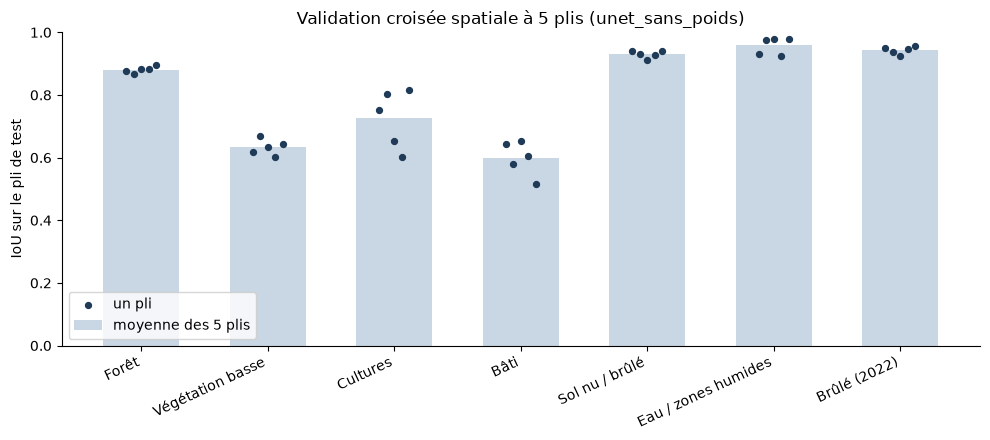

In [7]:
# IoU par classe pour chaque pli : un point par pli, la barre = moyenne
fig, ax = plt.subplots(figsize=(10, 4.5))
etiquettes = NOMS + ["Brûlé (2022)"]
colonnes = [f"IoU {n} (toutes)" for n in NOMS] + ["IoU Sol nu / brûlé (2022)"]
moyennes = [resultats[c].mean() for c in colonnes]
ax.bar(range(len(colonnes)), moyennes, color="#c9d6e3", width=0.6, label="moyenne des 5 plis")
for k in range(N_PLIS):
    ax.scatter(np.arange(len(colonnes)) + (k - 2) * 0.06, [resultats.loc[k, c] for c in colonnes],
               s=18, color="#1f3b57", zorder=3, label="un pli" if k == 0 else None)
ax.set_xticks(range(len(colonnes)), etiquettes, rotation=25, ha="right")
ax.set_ylabel("IoU sur le pli de test")
ax.set_ylim(0, 1)
ax.set_title(f"Validation croisée spatiale à {N_PLIS} plis ({NOM_ESSAI})")
ax.legend(loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"validation_croisee_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Sauvegarde

In [8]:
sortie = {
    "essai": NOM_ESSAI,
    "hyperparametres": HP,
    "n_plis": N_PLIS,
    "par_pli": resultats.to_dict(orient="records"),
    "moyenne": resultats.drop(columns=["pli_test", "pli_val"]).mean().to_dict(),
    "ecart_type": resultats.drop(columns=["pli_test", "pli_val"]).std(ddof=1).to_dict(),
}
with open(MODELE_DIR / f"{NOM_ESSAI}_validation_croisee.json", "w") as f:
    json.dump(sortie, f, indent=2, ensure_ascii=False, default=float)
resultats.to_csv(MODELE_DIR / f"{NOM_ESSAI}_validation_croisee.csv", index=False)
print(f"-> modeles/{NOM_ESSAI}_validation_croisee.json et .csv")

-> modeles/unet_sans_poids_validation_croisee.json et .csv


## Notes pour le rapport
